# 01 数据地基：口径统一与漏报校正

**这一步要回答的问题**：三次普查的数字能不能直接拿来用？如果不能，差在哪里、怎么修？

人口债券模型的每个“现金流”（出生 = 发行、20 岁 = 入场、65 岁 = 兑付）都直接来自人口数。
输入错 10%，后面所有指标都错 10%。所以先把地基打牢。

本 notebook 做四件事：
1. **口径统一**：长表抽样数据按抽样比放大；2020 年 5 岁组拆成单岁。
2. **出生漏报检查**：同一出生队列在两次普查中的人数对比。
3. **死亡漏报检查**：广义增长平衡法（GGB）+ 与官方、联合国数据对比。
4. **校正**：死亡和出生的“水平”用官方汇总数校准，“年龄模式”保留普查。

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from iop import census, coverage, ddm, fertility, leecarter, lifetable, official, wpp
from iop.plotting import COLORS, SEX_STYLE, YEAR_STYLE, fan, percentiles, pyramid, setup

setup()
pd.set_option("display.precision", 3)
pd.set_option("display.width", 160)

## 1. 数据清单与口径

| 文件 | 内容 | 抽样？ | 年龄粒度 |
|---|---|---|---|
| 五-t0201 / 六-A0201 / 七-A0202 | 分年龄、性别人口 | 全量（短表） | 单岁 / 单岁 / **5 岁组** |
| 五-t0604 / 六-A0601 / 七-A0601 | 普查前 12 个月死亡 | 全量 | 单岁 / 5 岁组 / 5 岁组 |
| 五-l0601 / 六-A0112 / 七-A0110 | 普查前 12 个月出生 | **2000 年为长表** / 全量 / 全量 | — |
| 五-l0606 / 六-B0603 / 七-B0603 | 育龄妇女分年龄、孩次生育 | **长表抽样** | 单岁 |

**旧模型的单位 bug 就出在这里**：2000 年出生数（118 万）和三张生育表里的妇女数都来自约 10% 的长表抽样，
直接和全量人口混用，早期出生队列就小了约 10 倍。

**抽样比怎么定**：不用猜，直接算——长表育龄妇女数 ÷ 短表（全量）15–49 岁女性人口。

In [2]:
summary = census.summary()
summary["births_万"] = summary["births"] / 1e4
summary[["population", "births_万", "deaths", "tfr", "sample_fraction"]]

,population,births_万,deaths,tfr,sample_fraction
year,,,,,
2000,1.243e+09,1262.805,7.313e+06,1.221,0.094
2010,1.333e+09,1383.619,7.422e+06,1.188,0.094
2020,1.410e+09,1200.469,7.966e+06,1.296,0.101


三年的抽样比都在 9.4%–10.1%，与国家统计局公布的“长表抽取 10% 左右住户”一致。
2000 年出生数按抽样比放大后约 1263 万（原来误用为 118 万）。

## 2. 2020 年：5 岁组 → 单岁

2020 年人口只有 5 岁组。旧模型按组内均匀分布拆分，会在每个组边界产生台阶。这里改用
**累计人数的单调样条（PCHIP）**：在组边界上构造累计人数 $N(x)$，平滑插值后对整数年龄差分。
这样每个单岁都非负，且各组合计**严格不变**。

0–4 岁组内出生数下降很快（2016 年约 1800 万 → 2020 年约 1200 万），样条会把 0 岁拆多，
所以 0 岁单独用“普查前 12 个月出生 − 婴儿死亡”锚定。

下图把拆分结果与联合国 WPP 的 2021 年 1 月 1 日单岁人口（独立来源）对比。

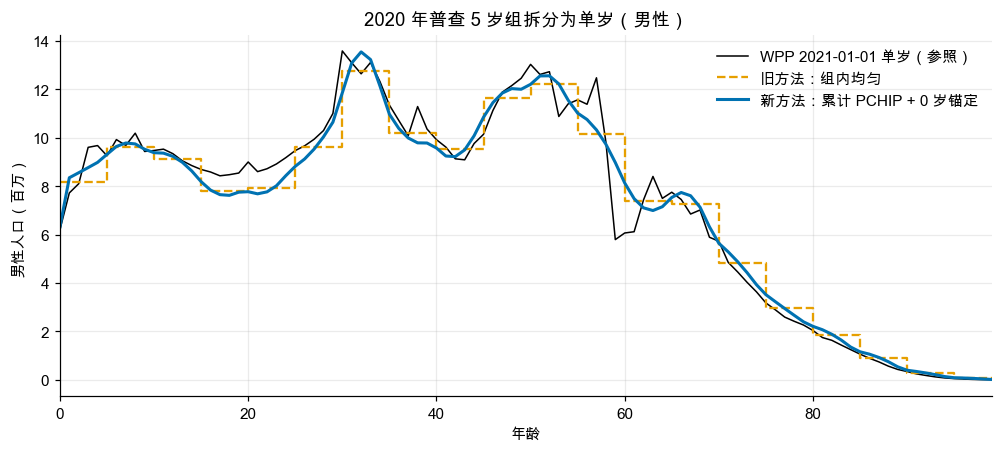

In [3]:
pop20 = census.population(2020)
w21 = wpp.population_jan1().loc[2021]
groups = census.population_groups(2020)
uniform = pd.Series(np.repeat(groups["male"].to_numpy()[:-1] / 5, 5), index=range(0, 100))

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(w21.index, w21["male"] / 1e6, color=COLORS["black"], lw=1, label="WPP 2021-01-01 单岁（参照）")
ax.step(uniform.index, uniform / 1e6, where="post", color=COLORS["orange"], ls="--", label="旧方法：组内均匀")
ax.plot(pop20.index[:-1], pop20["male"].iloc[:-1] / 1e6, color=COLORS["blue"], lw=2, label="新方法：累计 PCHIP + 0 岁锚定")
ax.set(xlabel="年龄", ylabel="男性人口（百万）", title="2020 年普查 5 岁组拆分为单岁（男性）", xlim=(0, 99))
ax.legend()
plt.show()

新方法消除了台阶，整体形状与 WPP 吻合。它**做不到**的是恢复组内的尖峰（例如某一年出生特别多），
因为 5 岁组里根本没有这个信息——这是数据本身的限制，在报告中要说明。

三次普查的人口金字塔：

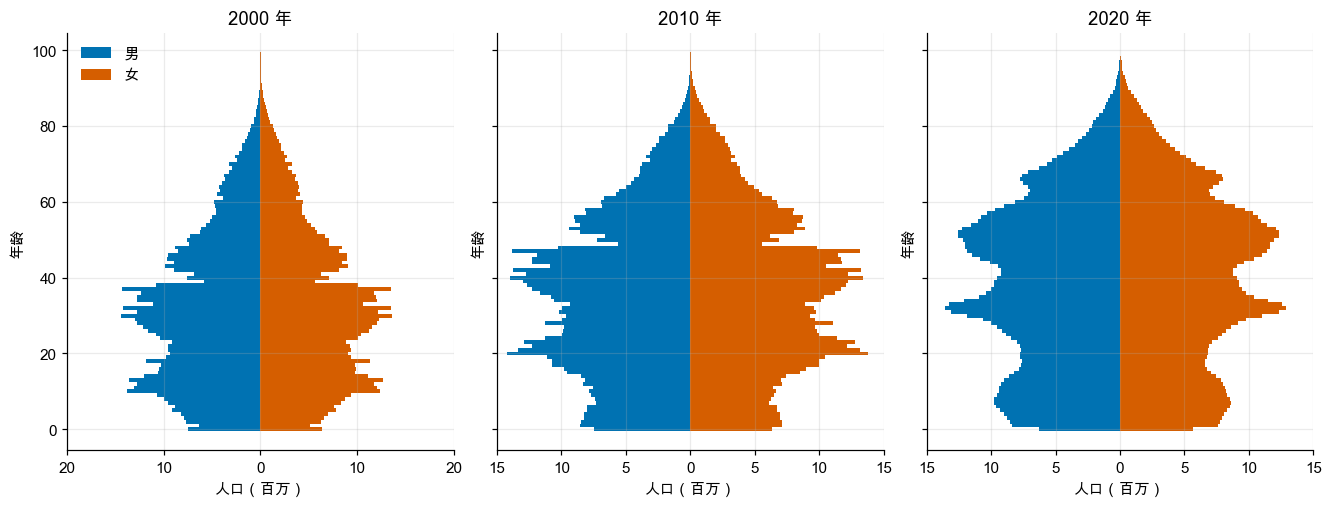

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(12, 4.5), sharey=True)
for ax, year in zip(axes, census.YEARS):
    pyramid(ax, census.population(year).loc[:99], f"{year} 年")
axes[0].legend(loc="upper left")
plt.show()

## 3. 出生漏报：队列一致性检验

**思路**：2000 年普查时 0–4 岁的孩子，2010 年普查时是 10–14 岁。十年里儿童死亡很少、国际迁移可以忽略，
所以两次普查人数应该**差不多（略少）**。如果后一次明显更多，说明前一次漏登了孩子。

In [5]:
cc = coverage.cohort_consistency()
cc[["cohort_born", "census1", "age1", "pop1", "census2", "age2", "pop2", "ratio"]]

,cohort_born,census1,age1,pop1,census2,age2,pop2,ratio
0,1996-2000,2000,0-4,6.898e+07,2010,10-14,7.491e+07,1.086
1,1991-1995,2000,5-9,9.015e+07,2010,15-19,9.989e+07,1.108
2,1986-1990,2000,10-14,1.254e+08,2010,20-24,1.274e+08,1.016
3,1981-1985,2000,15-19,1.030e+08,2010,25-29,1.010e+08,0.980
4,1976-1980,2000,20-24,9.457e+07,2010,30-34,9.714e+07,1.027
5,1971-1975,2000,25-29,1.176e+08,2010,35-39,1.180e+08,1.004
6,2006-2010,2010,0-4,7.553e+07,2020,10-14,8.526e+07,1.129
7,2001-2005,2010,5-9,7.088e+07,2020,15-19,7.268e+07,1.025
8,1996-2000,2010,10-14,7.491e+07,2020,20-24,7.494e+07,1.000
9,1991-1995,2010,15-19,9.989e+07,2020,25-29,9.185e+07,0.919


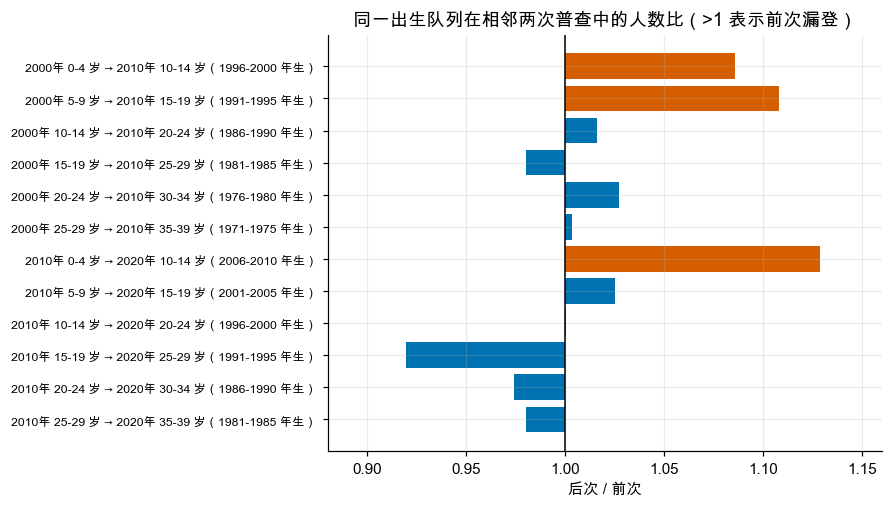

In [6]:
fig, ax = plt.subplots(figsize=(8, 4.5))
labels = [f"{r.census1}年 {r.age1} 岁 → {r.census2}年 {r.age2} 岁（{r.cohort_born} 年生）" for r in cc.itertuples()]
colors = [COLORS["vermillion"] if r > 1.05 else COLORS["blue"] for r in cc["ratio"]]
y = np.arange(len(cc))[::-1]
ax.barh(y, cc["ratio"] - 1.0, left=1.0, color=colors)
ax.axvline(1.0, color=COLORS["black"], lw=1)
ax.set_yticks(y, labels, fontsize=8)
ax.set(xlabel="后次 / 前次", title="同一出生队列在相邻两次普查中的人数比（>1 表示前次漏登）", xlim=(0.88, 1.16))
plt.show()

**读图**：2000 年普查的 0–9 岁、2010 年普查的 0–4 岁儿童，在下一次普查中“多出来” 9%–13%（红色）；
而 10 岁以上的队列比值都在 1 附近或略低于 1（略低于 1 是死亡与人口外流的正常结果）。
这是计划生育时期的经典现象：低龄儿童（尤其超生、女孩）在普查中被瞒报，长大上学、落户后才补登。

这意味着**普查直接算出的 TFR 偏低**。校正办法：用官方年度出生数（粗出生率 × 人口）校准出生水平。

In [7]:
fc = pd.DataFrame({y: coverage.fertility_coverage(y) for y in census.YEARS}).T
fc["tfr_wpp"] = [wpp.indicators().loc[y, "TFR"] for y in census.YEARS]
fc[["census_births", "official_births", "factor", "tfr_census", "tfr_adjusted", "tfr_wpp"]]

,census_births,official_births,factor,tfr_census,tfr_adjusted,tfr_wpp
2000,1.263e+07,1.743e+07,1.363,1.221,1.663,1.628
2010,1.384e+07,1.586e+07,1.230,1.188,1.461,1.687
2020,1.200e+07,1.201e+07,0.997,1.296,1.293,1.236


- 2000 年：普查 TFR 1.22，校正后约 1.66，与 WPP（1.63）接近。
- 2010 年：校正后约 1.46，WPP 为 1.69——WPP 还用了后续普查回推，校正幅度更大。
- 2020 年：普查与官方出生数几乎一致（系数 ≈ 1.00），说明 2020 年出生登记质量明显改善。

## 4. 死亡漏报

### 4.1 先看问题有多大
把普查死亡率除以 WPP 死亡率（=1 表示一致）：

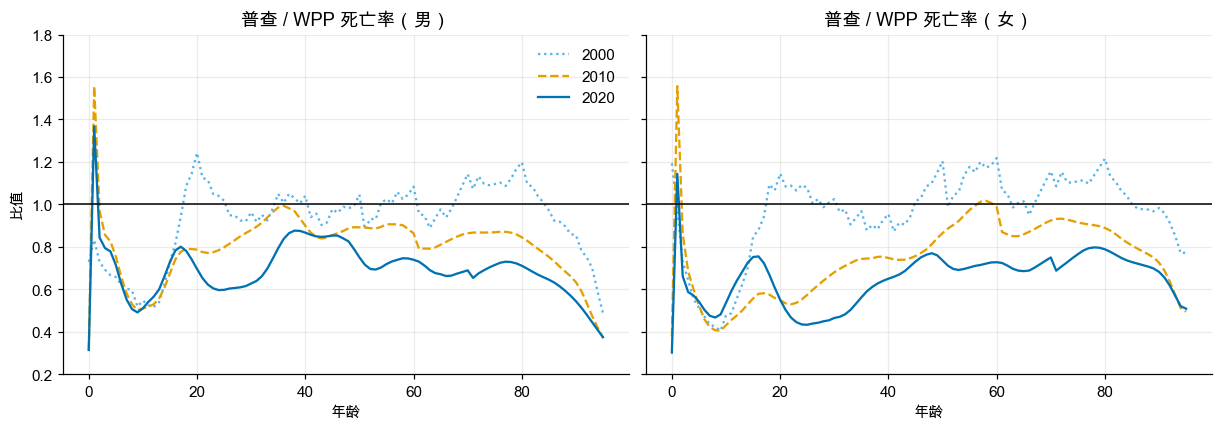

,普查死亡(万),WPP死亡(万),官方粗死亡率×人口(万),普查/官方
2000,731.308,778.005,801.485,0.912
2010,742.199,878.880,947.629,0.783
2020,796.577,1041.138,996.714,0.799


In [8]:
wm = wpp.mortality_rates()
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for ax, sex in zip(axes, ("male", "female")):
    for year in census.YEARS:
        ratio = census.mortality_rates(year)[sex].loc[:95] / wm[sex][year].loc[:95]
        st = YEAR_STYLE[year]
        ax.plot(ratio.index, ratio, color=st["color"], ls=st["ls"], label=str(year))
    ax.axhline(1, color=COLORS["black"], lw=1)
    ax.set(title=f"普查 / WPP 死亡率（{SEX_STYLE[sex]['label']}）", xlabel="年龄", ylim=(0.2, 1.8))
axes[0].set_ylabel("比值")
axes[0].legend()
plt.show()

cmp = pd.DataFrame(
    {y: {"普查死亡(万)": census.deaths_groups(y)[["male", "female"]].to_numpy().sum() / 1e4,
         "WPP死亡(万)": wpp.deaths().loc[y].to_numpy().sum() / 1e4,
         "官方粗死亡率×人口(万)": official.CRUDE_DEATH_RATE[y] * census.population(y).to_numpy().sum() / 1e4}
     for y in census.YEARS}).T
cmp["普查/官方"] = cmp["普查死亡(万)"] / cmp["官方粗死亡率×人口(万)"]
cmp

- 2000 年普查与 WPP 大致一致；**2010、2020 年普查死亡明显偏少**：2010 年成年段约低 10%–20%，2020 年约低 20%–35%，90 岁以上更严重。
- 婴儿死亡（0 岁）漏报最严重：2020 年普查算出的婴儿死亡率约 1.7‰，卫健委监测为 5.4‰。

为什么会漏？普查登记的是“过去 12 个月户内死亡”，独居老人去世后整户消失、婴儿出生后很快死亡等都容易漏报。

### 4.2 只用普查本身能估计漏报吗？——广义增长平衡法（GGB）

GGB（Hill 1987）是人口学里标准的“死亡分布法”，**只用两次普查 + 死亡登记**就能估计死亡登记完整度。

对 $x$ 岁以上的人群：进入率 − 增长率 = 真实死亡率。若登记完整度为 $c$，则
$$
b(x+) - r(x+) = k + \frac{1}{c}\, d_{\text{obs}}(x+)
$$
对不同起始年龄 $x$ 画散点，应近似一条直线：**斜率的倒数 = 死亡登记完整度**。

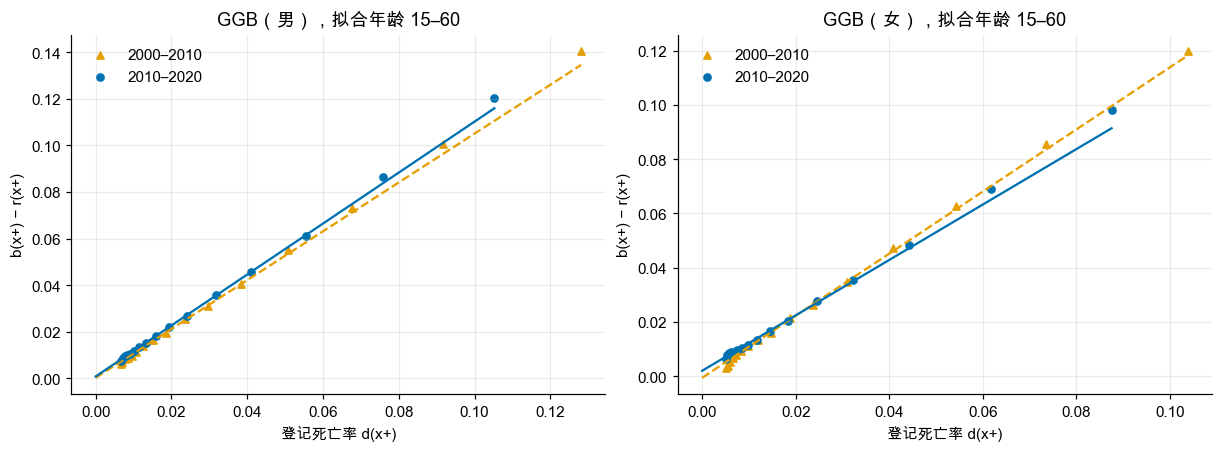

,性别,区间,完整度 c,相对覆盖率
0,男,2000-2010,0.954,1.003
1,男,2010-2020,0.914,1.009
2,女,2000-2010,0.874,0.994
3,女,2010-2020,0.979,1.021


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
rows = []
for ax, sex in zip(axes, ("male", "female")):
    for (y1, y2), st in zip(((2000, 2010), (2010, 2020)), (YEAR_STYLE[2010], YEAR_STYLE[2020])):
        res = ddm.ggb(y1, y2, sex)
        t = res["table"].loc[5:80]
        ax.scatter(t["d"], t["b_minus_r"], color=st["color"], marker=st["marker"], s=22, label=f"{y1}–{y2}")
        xs = np.linspace(0, t["d"].max(), 10)
        ax.plot(xs, res["intercept"] + res["slope"] * xs, color=st["color"], ls=st["ls"])
        rows.append({"性别": SEX_STYLE[sex]["label"], "区间": f"{y1}-{y2}", "完整度 c": res["completeness"], "相对覆盖率": res["relative_coverage"]})
    ax.set(title=f"GGB（{SEX_STYLE[sex]['label']}），拟合年龄 15–60", xlabel="登记死亡率 d(x+)", ylabel="b(x+) − r(x+)")
    ax.legend()
plt.show()
pd.DataFrame(rows)

GGB 估计成年死亡登记完整度约 0.87–0.98，**方向一致（有漏报），但幅度比官方/WPP 对比显示的小**。原因是 GGB 的几个假设在中国数据里不严格成立：
- 两次普查的死亡完整度相同（实际 2000 年明显好于 2010、2020 年，会让斜率被低估）；
- 年龄申报准确、人口封闭（高龄年龄夸报、流动人口重复/遗漏登记都会干扰）；
- 只拟合 15–60 岁，而漏报主要集中在高龄。

**结论**：GGB 证明“普查死亡有漏报”是数据内部就能看出来的，但不足以给出准确的校正幅度。所以采用下面的外部校准。

### 4.3 校正方案：水平用官方，模式用普查

| 年龄段 | 校准目标 | 来源 |
|---|---|---|
| 0 岁 | 婴儿死亡率 | 卫健委妇幼监测 |
| 1–4 岁 | 5 岁以下儿童死亡率 | 卫健委妇幼监测 |
| 5 岁以上 | 口径 A：死亡总数 = 官方粗死亡率 × 人口；口径 B：分性别 e0 = 官方平均预期寿命 | 国家统计局 |
| 90 岁以上 | Kannisto 曲线外推（见 notebook 02） | — |

In [10]:
rows = []
for y in census.YEARS:
    raw = census.mortality_rates(y)
    for target in ("deaths", "e0"):
        r = coverage.adjusted_mortality(y, target=target)
        rows.append({
            "年份": y, "口径": "A 对齐死亡总数" if target == "deaths" else "B 对齐 e0",
            "0岁系数": r["factors"]["infant"], "成人系数(男)": r["factors"]["adult_male"], "成人系数(女)": r["factors"]["adult_female"],
            "e0 男": lifetable.e0(r["mx"]["male"], "male"), "e0 女": lifetable.e0(r["mx"]["female"], "female"),
            "隐含死亡/官方": r["implied_deaths"] / (official.CRUDE_DEATH_RATE[y] * census.population(y).to_numpy().sum()),
        })
    rows.append({"年份": y, "口径": "原始普查", "e0 男": lifetable.e0(lifetable.kannisto_close(raw["male"]), "male"),
                 "e0 女": lifetable.e0(lifetable.kannisto_close(raw["female"]), "female")})
    rows.append({"年份": y, "口径": "官方公布", "e0 男": official.LIFE_EXPECTANCY[y]["male"], "e0 女": official.LIFE_EXPECTANCY[y]["female"]})
    rows.append({"年份": y, "口径": "WPP", "e0 男": wpp.indicators().loc[y, "LExMale"], "e0 女": wpp.indicators().loc[y, "LExFemale"]})
pd.DataFrame(rows).set_index(["年份", "口径"])

0岁系数  成人系数(男)  成人系数(女)    e0 男    e0 女  隐含死亡/官方
年份   口径                                                        
2000 A 对齐死亡总数  1.231    1.034    1.034  69.801  73.338    1.001
     B 对齐 e0   1.231    1.051    1.035  69.630  73.330    1.010
     原始普查        NaN      NaN      NaN  70.632  74.327      NaN
     官方公布        NaN      NaN      NaN  69.630  73.330      NaN
     WPP         NaN      NaN      NaN  69.850  74.895      NaN
2010 A 对齐死亡总数  3.041    1.303    1.303  72.422  77.496    1.000
     B 对齐 e0   3.041    1.308    1.319  72.380  77.370    1.008
     原始普查        NaN      NaN      NaN  76.062  80.876      NaN
     官方公布        NaN      NaN      NaN  72.380  77.370      NaN
     WPP         NaN      NaN      NaN  73.191  78.329      NaN
2020 A 对齐死亡总数  3.125    1.285    1.285  76.500  81.967    1.003
     B 对齐 e0   3.125    1.423    1.443  75.370  80.880    1.117
     原始普查        NaN      NaN      NaN  79.661  84.650      NaN
     官方公布        NaN      NaN      NaN  75.370  80.880      NaN
     WPP         NaN      NaN      NaN  75.245  80.999      NaN

**读表**：
- 原始普查 2020 年 e0 男约 79.7、女约 84.7，比官方高 4 岁左右——直接用会严重高估老年人口、低估养老“兑付”的结束速度。
- 2000、2010 年两种口径几乎一致，说明“整体等比例漏报”的假设在这两年成立。
- 2020 年两种口径冲突：对齐死亡总数时 e0 仍偏高约 1.1 岁；对齐 e0 时隐含死亡比官方多约 12%。
  说明 2020 年**高龄段漏报比中年段更重**。由于官方 e0 与 WPP（独立估计）高度一致，**后续预测采用口径 B 作为基年死亡率**。

## 小结

| 问题 | 发现 | 处理 |
|---|---|---|
| 长表抽样混用 | 抽样比 9.4%–10.1% | 按实际抽样比放大 |
| 2020 年只有 5 岁组 | 均匀拆分产生台阶 | 累计 PCHIP + 0 岁出生锚定 |
| 儿童漏登 | 0–9 岁下次普查多出 9%–13% | 出生水平按官方出生数校准 |
| 死亡漏报 | 2020 年普查死亡只有官方的 80% | 分年龄段校准到官方 IMR / U5MR / e0 |

> **对导师怎么说**：原模型直接使用普查原始数，存在三类口径问题——长表抽样与全量混用（导致出生队列低估一个数量级）、
> 儿童漏登（普查 TFR 低估约 25%）、死亡漏报（2020 年普查 e0 高估约 4 岁）。我用队列一致性检验和广义增长平衡法
> 从数据内部确认了漏报的存在和方向，再以官方汇总指标校准水平、保留普查的年龄模式，校正后的生命表与官方 e0 误差在 0.2 岁以内（2000、2010 年）。